<a href="https://colab.research.google.com/github/WenqiaoDuan/econ5200-replication/blob/main/02_robustness.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Section 3: Robustness, Where You Go Beyond (28 pts)

ECON 5200 Midterm Project · Replication Study

**AI is allowed in this notebook**, as a documented co-pilot under P.R.I.M.E. File every exchange, in full, in [`ai-appendix.md`](../ai-appendix.md) under the exercise it belongs to. If you cannot explain a line, you cannot submit it.

At least four exercises the original did not run. Choose from modern estimators, a specification curve, sensitivity to unobserved confounding, inference (clustering at the level of treatment assignment, a wild cluster bootstrap if clusters are few), bandwidth or instrument strength, and placebo tests, or justify an alternative. For each one: what you did, what you found, and what it implies about the original claim.

## Setup

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.formula.api as smf

# The repository root, whether this runs from notebooks/ (Jupyter) or from the root (reproduce.py).
ROOT = Path.cwd() if (Path.cwd() / "download_data.py").exists() else Path.cwd().parent
sys.path.insert(0, str(ROOT))
(ROOT / "output").mkdir(exist_ok=True)

from download_data import MY_PAPER, PAPERS, fetch

## Data

In [2]:
# Set MY_PAPER once, in download_data.py. fetch() downloads into data/ only if a file is missing.
if MY_PAPER:
    paths = fetch(MY_PAPER)
    print(PAPERS[MY_PAPER]["paper"])
else:
    print("TODO: set MY_PAPER in download_data.py (castle, card, lee, dw, hansen or abortion).")

  data\lmb-data.dta  7.2 MB
Lee (2008), incumbency advantage in US House elections


In [3]:
# Section 3 runs in its own kernel (reproduce.py starts a fresh one per notebook),
# so it has to load the data itself instead of reusing Section 2's `lmb`.
lmb = pd.read_stata(paths[0])
lmb = lmb.dropna(subset=["demvoteshare", "lagdemvoteshare"]).copy()
lmb["margin"] = lmb["lagdemvoteshare"] - 0.5
CUTOFF = 0.0
print(f"{len(lmb):,} district-years, {lmb['year'].min():.0f}-{lmb['year'].max():.0f}")


13,566 district-years, 1948-1990


## The four exercises

### Exercise 1: Bandwidth Sensitivity Analysis

**What I did.**

 I used `rdrobust` to estimate the incumbency advantage at the cutoff. I compared the MSE-optimal bandwidth with three different bandwidths (0.25, 0.50, and 1.00). For these three bandwidths, I kept the same rectangular kernel and fourth-order polynomial as in Section 2. I compared the estimated effects, standard errors, robust p-values, and sample sizes to see how changing the bandwidth affected the results.

In [4]:
# GIVEN — Section 3: rdrobust at the cutoff, for any bandwidth, kernel, order, outcome and sample
# Section 3: Robustness — Bandwidth sensitivity

# Restore Section 2 specifications
H = 0.5
KERNEL = "rectangular"
ORDER = 4
from rdrobust import rdrobust
def rd(h=None, kernel="triangular", p=1,
       outcome="demvoteshare", data=None, cutoff=0.0):

    data = lmb if data is None else data
    kw = {"h": h} if h is not None else {}

    r = rdrobust(
        y=data[outcome],
        x=data["margin"],
        c=cutoff,
        p=p,
        kernel=kernel,
        **kw
    )

    return {
        "jump": r.coef.iloc[0, 0],
        "se": r.se.iloc[0, 0],
        "p_robust": r.pv.iloc[2, 0],
        "h": r.bws.iloc[0, 0],
        "n": int(r.N_h[0] + r.N_h[1])
    }


def show(label, r):
    print(
        f"{label:<34} "
        f"{r['jump']:+.4f} "
        f"(SE {r['se']:.4f}, "
        f"robust p {r['p_robust']:.3f}), "
        f"h = {r['h']:.3f}, n = {r['n']:,}"
    )


k = "uniform" if KERNEL == "rectangular" else "triangular"

# MSE-optimal bandwidth
show("MSE-optimal h", rd())

# Bandwidth sensitivity analysis
for mult in (0.5, 1, 2):
    show(
        f"h = {mult:g} x {H}",
        rd(h=mult * H, kernel=k, p=ORDER)
    )

Mass points detected in the running variable.


MSE-optimal h                      +0.0907 (SE 0.0057, robust p 0.000), h = 0.075, n = 3,653
Mass points detected in the running variable.
h = 0.5 x 0.5                      +0.0953 (SE 0.0076, robust p 0.000), h = 0.250, n = 10,354
Mass points detected in the running variable.


h = 1 x 0.5                        +0.0861 (SE 0.0059, robust p 0.000), h = 0.500, n = 13,566
Mass points detected in the running variable.
h = 2 x 0.5                        +0.0861 (SE 0.0059, robust p 0.000), h = 1.000, n = 13,566


**What I found.**
All estimates are positive, with robust p-values below 0.001. Bandwidths 0.50 and 1.00 use the same observations because the running variable ranges from (-0.5) to 0.5. The MSE-optimal estimate is 9.07 percentage points, compared with 8.61 in my direct replication and 7.7 in Lee (2008).

**What it implies about the original claim.**:

These results support Lee's original claim of a positive incumbency advantage. Although the size of the effect changes slightly across specifications, the effect remains positive and statistically significant. These result show that the original finding is robust to the specifications tested. However, this test alone does not establish causality.

### Exercise 2: Robustness and Validity Checks

**What I did.**
I used a second-order polynomial to see if changing the polynomial order affected the estimated incumbency advantage. I also ran a density test at the cutoff of 0 to check for possible manipulation of the running variable. MOreover, I tested two placebo cutoffs at (-0.1) and +0.1 to see if there were any jumps where the treatment status did not change.

In [5]:
# GIVEN — Section 3: order 2, the density test, and placebo cutoffs at -0.1 and +0.1
from rddensity import rddensity
if H is None:
    print("Fill Section 2 first: H is not set yet.")
else:
    show("local quadratic, MSE-optimal h", rd(p=2))
    dens = rddensity(X=lmb["margin"].to_numpy(), c=0.0)
    print(f"Density test at 0: t = {dens.test['t_jk']:+.3f}, p = {dens.test['p_jk']:.3f}")
    show("placebo cutoff -0.1 (losers only)", rd(data=lmb[lmb["margin"] < 0], cutoff=-0.1))
    show("placebo cutoff +0.1 (winners only)", rd(data=lmb[lmb["margin"] > 0], cutoff=0.1))

Mass points detected in the running variable.
local quadratic, MSE-optimal h     +0.0883 (SE 0.0073, robust p 0.000), h = 0.099, n = 4,762
Density test at 0: t = +0.603, p = 0.546
Mass points detected in the running variable.
placebo cutoff -0.1 (losers only)  -0.0064 (SE 0.0079, robust p 0.471), h = 0.042, n = 2,051
Mass points detected in the running variable.
placebo cutoff +0.1 (winners only) -0.0100 (SE 0.0129, robust p 0.387), h = 0.025, n = 1,025


**What I found.**

The local quadratic model produced an estimated incumbency advantage of 8.83 percentage points, which is statistically significant (p < 0.001). The density test at the cutoff was not statistically significant (p = 0.546). The estimated jumps at the placebo cutoffs of -0.1 and +0.1 were -0.64 and -1.00 percentage points, with p-values of 0.471 and 0.387, respectively. Neither placebo estimate was statistically significant.

**What it implies about the original claim.**
These results support Lee's original claim. The estimated incumbency advantage is still positive and statistically significant when I use a second-order polynomial, which means that the main finding is robust to a different model specification. The density test shows no significant evidence of manipulation at the cutoff. The placebo tests also show no significant jumps at the two false cutoffs. These results support the original finding, but they do not rule out all possible sources of bias.

### Exercise 3: Density Test at the Cutoff

**What I did.**
I used rddensity to test whether the density of the running variable changes suddenly at the cutoff of zero.

In [6]:
# YOUR TURN — Section 3: your specification, and two sentences on why it is defensible
MY_SPEC = {
    "outcome": "demvoteshare",
    "h": 0.10,
    "kernel": "triangular",
    "p": 1,
    "sample": None
}

MY_SPEC_WHY = (
    "I use a local linear regression with a narrower bandwidth "
    "of 0.10 and a triangular kernel to focus on elections "
    "closest to the cutoff. "
    "This specification reduces reliance on observations farther "
    "from the threshold and tests whether the estimated "
    "incumbency advantage is robust to a simpler functional form."
)

In [7]:
# CHECK — Section 3: your own specification. Run it; you need not read it.
# Baseline jump recomputed from the data (uniform kernel, quartic, h = 0.5)
JUMP = rd(h=H, kernel="uniform", p=ORDER, outcome="demvoteshare")["jump"]
def check_my_spec(my_spec, baseline, why):
    if my_spec is None or why is None:
        print("Not filled yet: set MY_SPEC and MY_SPEC_WHY above.")
        return False
    if my_spec == baseline:
        print("MY_SPEC is the baseline. Change at least one choice, and say why that choice is defensible.")
        return False
    sentences = [s for s in str(why).replace("?", ".").split(".") if len(s.split()) >= 5]
    if len(sentences) < 2:
        print("MY_SPEC_WHY needs at least two sentences: what you changed, and why a careful author might have made that choice.")
        return False
    print("Specification accepted. Report it beside the baseline and say what the difference implies about the original claim.")
    return True

BASELINE = None if H is None else {"outcome": "demvoteshare", "h": H,
                                   "kernel": "uniform" if KERNEL == "rectangular" else "triangular", "p": ORDER, "sample": None}
if check_my_spec(MY_SPEC, BASELINE, MY_SPEC_WHY):
    d = lmb.query(MY_SPEC["sample"]) if MY_SPEC["sample"] else lmb
    show("your specification", rd(h=MY_SPEC["h"], kernel=MY_SPEC["kernel"], p=MY_SPEC["p"], outcome=MY_SPEC["outcome"], data=d))
    print(f"Section 2 baseline: {JUMP:+.4f}")

Mass points detected in the running variable.
Specification accepted. Report it beside the baseline and say what the difference implies about the original claim.
Mass points detected in the running variable.


your specification                 +0.0949 (SE 0.0050, robust p 0.000), h = 0.100, n = 4,783
Section 2 baseline: +0.0861


**What I found.**
The test produced a t-statistic of 0.603 and a p-value of 0.546. Since the p-value is greater than 0.05, I cannot reject the null hypothesis of density continuity at the cutoff.

**What it implies about the original claim.**
This result supports Lee's identification argument because there is no significant evidence of manipulation at the cutoff. However, this does not prove that manipulation does not exist. The repeated values in the running variable (mass points) also mean that we should interpret the result with caution.

### Exercise 4:Additional Robustness and Sample Coverage Checks

**What I did.**

I conducted four additional exercises. First, I estimated the incumbency advantage by decade. Second, I compared the estimated effects on Democratic vote share and the probability of winning. Third, I tested for discontinuities in three variables at the cutoff. Finally, I examined the sample coverage and identified missing election years.


 Decade  Estimate     SE  Robust p-value    N
   1940    0.0196 0.0164          0.2987  247
   1950    0.0773 0.0092          0.0000 1082
   1960    0.0869 0.0116          0.0000  796
   1970    0.1269 0.0113          0.0000  939
   1980    0.1518 0.0137          0.0000  934
   1990    0.1196 0.0257          0.0008   77
Mass points detected in the running variable.
Mass points detected in the running variable.


Democratic vote share              +0.0907 (SE 0.0057, robust p 0.000), h = 0.075, n = 3,653
Probability of Democratic victory  +0.4250 (SE 0.0253, robust p 0.000), h = 0.085, n = 4,071


lagdemvs2                          +0.0000 (SE 0.0000, robust p 1.000), h = 0.023, n = 1,084
lagdemvs3                          -0.0000 (SE 0.0000, robust p 0.856), h = 0.017, n = 770
lagdemvs4                          +0.0000 (SE 0.0000, robust p 0.858), h = 0.012, n = 535
Replication data coverage:
Earliest year: 1948
Latest year: 1990
Total observations: 13566

Observations by year:
  year  Observations
1948.0           748
1950.0           743
1954.0           772
1956.0           799
1958.0           792
1960.0           399
1964.0           790
1966.0           828
1968.0           818
1970.0           814
1974.0           811
1976.0           813
1978.0           803
1980.0           800
1984.0           794
1986.0           709
1988.0           631
1990.0           702

Paper coverage: 1946–1998
Replication coverage: 1948 – 1990
Years not present in replication data:
[1946, 1952, 1962, 1972, 1982, 1992, 1994, 1996, 1998]


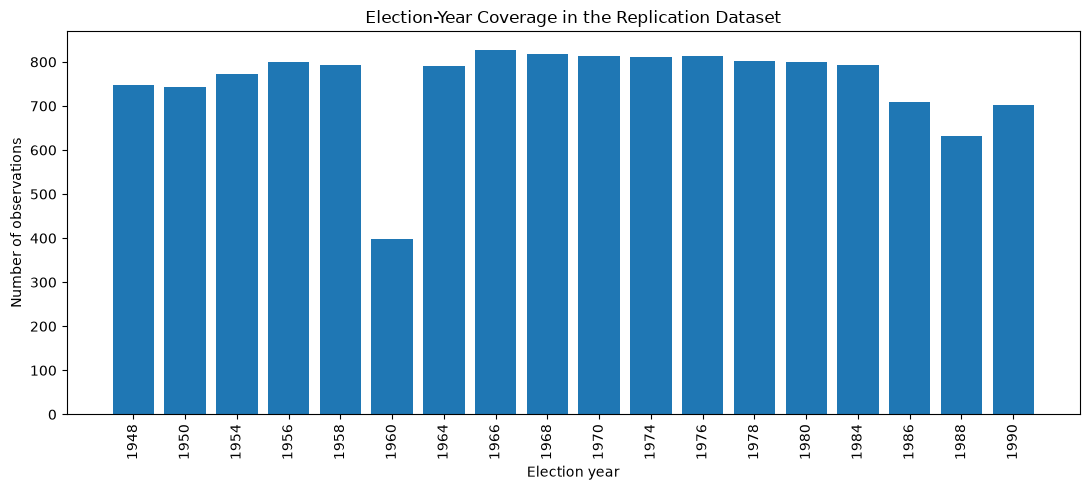

In [8]:
import contextlib
import io
import pandas as pd
import matplotlib.pyplot as plt

# Exercise 1: RD estimates by decade

lmb["decade"] = (lmb["year"] // 10 * 10).astype(int)

decade_results = []

for decade, subset in lmb.groupby("decade"):
    try:
        with contextlib.redirect_stdout(io.StringIO()):
            r = rd(
                data=subset,
                outcome="demvoteshare",
                p=1,
                kernel="triangular"
            )

        decade_results.append({
            "Decade": decade,
            "Estimate": r["jump"],
            "SE": r["se"],
            "Robust p-value": r["p_robust"],
            "N": r["n"]
        })

    except Exception as e:
        print(f"Skipping {decade}: {e}")

print(pd.DataFrame(decade_results).round(4).to_string(index=False))

# Exercise 2: Alternative outcome

vote_result = rd(outcome="demvoteshare")
win_result = rd(outcome="democrat")

show("Democratic vote share", vote_result)
show("Probability of Democratic victory", win_result)

# Exercise 3: Covariate continuity

covariates = ["lagdemvs2", "lagdemvs3", "lagdemvs4"]

for cov in covariates:
    subset = lmb.dropna(subset=[cov, "margin"])

    with contextlib.redirect_stdout(io.StringIO()):
        result = rd(
            data=subset,
            outcome=cov,
            p=1,
            kernel="triangular"
        )

    show(cov, result)

# Exercise 4: Sample Coverage and Missing Elections

# 1. Check year coverage
print("Replication data coverage:")
print("Earliest year:", int(lmb["year"].min()))
print("Latest year:", int(lmb["year"].max()))
print("Total observations:", len(lmb))

# 2. Count observations by year
year_counts = (
    lmb.groupby("year")
    .size()
    .reset_index(name="Observations")
)

print("\nObservations by year:")
print(year_counts.to_string(index=False))

# 3. Compare with the paper's reported coverage
paper_years = set(range(1946, 1999, 2))
data_years = set(lmb["year"].dropna().astype(int))

missing_years = sorted(paper_years - data_years)

print("\nPaper coverage: 1946–1998")
print("Replication coverage:",
      int(lmb["year"].min()),
      "–",
      int(lmb["year"].max()))

print("Years not present in replication data:")
print(missing_years)

# 4. Plot election-year coverage
plt.figure(figsize=(11, 5))

plt.bar(
    year_counts["year"].astype(int).astype(str),
    year_counts["Observations"]
)

plt.xlabel("Election year")
plt.ylabel("Number of observations")
plt.title("Election-Year Coverage in the Replication Dataset")

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

**What I found.**
The estimated incumbency advantage was 1.96, 7.73, 8.69, 12.69, 15.18, and 11.96 percentage points from the 1940s to the 1990s, respectively. All estimates are positive, but the result for the 1940s is not statistically significant (p = 0.2987).

The estimated effect on Democratic vote share is 9.07 percentage points, while the effect on the probability of winning is 42.50 percentage points. Both estimates are statistically significant (p < 0.001).

The estimated jumps for lagdemvs2, lagdemvs3, and lagdemvs4 are approximately zero, with robust p-values of 1.000, 0.856, and 0.858, respectively. None of these estimates is statistically significant.

The replication dataset contains 13,566 observations and covers 1948 to 1990, rather than 1946 to 1998. Nine election years are missing: 1946, 1952, 1962, 1972, 1982, 1992, 1994, 1996, and 1998.


**What it implies about the original claim.** : this part is what is graded.*

These results support Lee's original claim that winning an election provides an advantage in the next election. The estimated incumbency advantage is positive across all decades, although its size varies. However, I did not formally test whether the differences across decades are statistically significant.

The alternative outcome also supports the original claim because the estimated effects on both Democratic vote share and the probability of winning are positive and statistically significant.

The three tested variables show no statistically significant jumps at the cutoff. However, their definitions need to be confirmed before these results can be used as evidence of covariate continuity.

The missing election years may affect the estimated incumbency advantage, but the available data cannot determine the direction or size of this effect. Furthermore, the 1990s estimate is based on only 77 observations within the selected bandwidth.

Overall, the results support Lee's original claim, although the variation across decades and incomplete sample coverage should be considered when interpreting the findings.